<a href="https://colab.research.google.com/github/Yosef-Dantas/Wine-Classification-Knn-And-Random-Forest/blob/main/Classificacao_Vinhos_KNN_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ciência de Dados

### O Conjunto de *Dados Wine Quality*

Este trabalho apresenta a aplicação de técnicas de Ciência de Dados e Aprendizado de Máquina para a classificação de vinhos tintos e brancos a partir de suas propriedades físico-químicas.

O estudo utiliza o conjunto de dados Wine Quality, disponibilizado pelo UCI Machine Learning Repository, e compara o desempenho dos algoritmos K-Nearest Neighbors (KNN) e Random Forest em um problema de classificação binária.

A implementação utiliza as bibliotecas Pandas, NumPy e Matplotlib para manipulação, análise e visualização dos dados, além do Scikit-learn para preparação, treinamento, otimização e avaliação dos modelos e do Joblib para armazenamento do modelo final.

## Importações das Bibliotecas

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score
)

## Carregamento dos Dados e Análise Exploratória de Dados (EDA)

### 1. Carregamento e inspeção inicial dos dados

Os conjuntos de dados referentes aos vinhos tintos e brancos são carregados diretamente a partir do UCI Machine Learning Repository. Em seguida, é criada a variável wine_type, responsável por identificar o tipo de vinho, e os dois conjuntos são combinados em um único DataFrame para as etapas posteriores de análise.

In [70]:
url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

wine_red = pd.read_csv(url_red, sep=";")
wine_white = pd.read_csv(url_white, sep=";")

wine_red["wine_type"] = "red"
wine_white["wine_type"] = "white"

wine = pd.concat(
    [wine_red, wine_white],
    ignore_index=True
)

Realiza-se a inspeção inicial do DataFrame por meio do método `head()`, exibindo as cinco primeiras linhas com o intuito de verificar a estrutura das colunas e a organização geral dos registros.

In [71]:
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


### 2. Estrutura do conjunto de dados

Para compreender a dimensão do espaço amostral e a quantidade de atributos, determinam-se as dimensões de linhas e colunas do conjunto de dados.

In [72]:
registros, variaveis = wine.shape
print(f"O conjunto de dados possui {registros} registros e {variaveis} variáveis.")

O conjunto de dados possui 6497 registros e 13 variáveis.


A seguir, listam-se os rótulos das colunas do DataFrame para identificação exata das variáveis disponíveis para o mapeamento e modelagem.

In [73]:
wine.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'wine_type'],
      dtype='object')

O conjunto de dados combinado possui 13 variáveis. Destas, 11 representam propriedades físico-químicas dos vinhos, a variável quality representa a avaliação de qualidade presente no conjunto original e a variável wine_type, criada neste estudo, identifica o tipo de vinho como red ou white.

Procede-se à identificação dos tipos de dados de cada coluna, etapa importante para distinguir as variáveis numéricas da variável categórica utilizada como alvo da classificação.

In [74]:
wine.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


A identificação dos tipos de dados mostra que as propriedades físico-químicas dos vinhos são representadas por variáveis numéricas, enquanto quality corresponde a uma variável numérica discreta e wine_type é uma variável categórica utilizada como alvo da classificação. Como as variáveis preditoras utilizadas no modelo serão numéricas, não será necessária a codificação de atributos categóricos. A necessidade de padronização será considerada de acordo com as características de cada algoritmo.

Abaixo, é apresentada a síntese estrutural do DataFrame, detalhando a contagem de registros não nulos por coluna e o consumo de memória do objeto.

In [75]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


### 3. Análise de valores ausentes

Após a inspeção estrutural do conjunto de dados, verifica-se a presença de valores ausentes em cada variável. Essa etapa é importante para identificar possíveis lacunas que poderiam afetar as análises estatísticas e o treinamento dos modelos.

In [76]:
valores_ausentes = wine.isnull().sum()

percentual_ausentes = (
    valores_ausentes / wine.shape[0]
) * 100

analise_valores_ausentes = pd.DataFrame({
    'Valores ausentes': valores_ausentes,
    'Percentual (%)': percentual_ausentes.round(2)
})

analise_valores_ausentes = analise_valores_ausentes.sort_values(
    by='Percentual (%)',
    ascending=False
)

analise_valores_ausentes

,Valores ausentes,Percentual (%)
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


A análise demonstra que todas as variáveis do conjunto de dados estão completamente preenchidas, não sendo identificados valores ausentes. Dessa forma, não será necessária a aplicação de técnicas de imputação antes das etapas de análise e modelagem.

### 4. Verificação de registros duplicados

Além dos valores ausentes, é importante verificar a existência de registros duplicados no conjunto de dados. Registros repetidos podem influenciar as análises estatísticas e o treinamento dos modelos ao atribuir maior peso a determinadas observações.

In [77]:
duplicados = wine.duplicated().sum()

print(f"Quantidade de registros duplicados: {duplicados}")

Quantidade de registros duplicados: 1177


In [78]:
wine = wine.drop_duplicates().reset_index(drop=True)

print(f"Quantidade de registros após a remoção: {wine.shape[0]}")

Quantidade de registros após a remoção: 5320


Foram identificados 1.177 registros duplicados no conjunto de dados. Como registros idênticos podem atribuir peso excessivo a determinadas observações e favorecer uma avaliação artificialmente otimista dos modelos, optou-se pela remoção das duplicatas antes da separação entre os conjuntos de treinamento e teste. Após esse procedimento, o conjunto passou a possuir 5.320 registros únicos.

### 5. Análise da variável alvo

A variável wine_type representa o alvo do problema de classificação, indicando se cada amostra corresponde a um vinho tinto (red) ou branco (white). Inicialmente, analisa-se a distribuição das classes para verificar possíveis desequilíbrios que possam influenciar o treinamento e a avaliação dos modelos.

In [79]:
print(wine["wine_type"].value_counts())

print("\nPercentual:")
print((wine["wine_type"].value_counts(normalize=True) * 100).round(2))

wine_type
white    3961
red      1359
Name: count, dtype: int64

Percentual:
wine_type
white    74.45
red      25.55
Name: proportion, dtype: float64


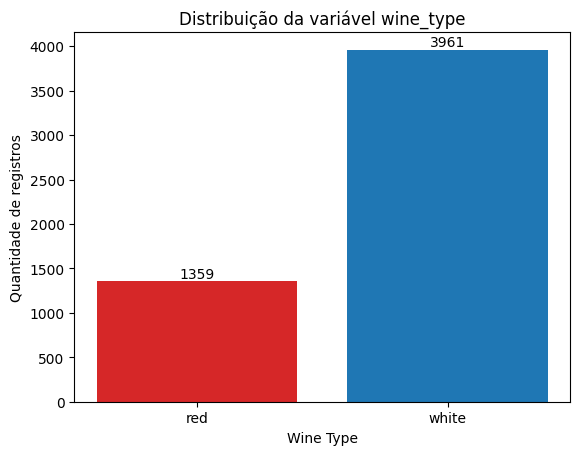

In [80]:
contagem = wine["wine_type"].value_counts()
contagem = contagem.reindex(["red", "white"])

x = contagem.index
y = contagem.values

fig, ax = plt.subplots()

barras = ax.bar(x, y, color=['tab:red', 'tab:blue'])

ax.set_xlabel('Wine Type')
ax.set_ylabel('Quantidade de registros')
ax.set_title("Distribuição da variável wine_type")

ax.bar_label(barras)

plt.show()

Após a remoção dos registros duplicados, a variável alvo wine_type apresenta desbalanceamento entre as classes, com maior quantidade de amostras da classe white em relação à classe red. Para preservar essa proporção nos conjuntos de treinamento e teste, será utilizada a divisão estratificada dos dados.

Optou-se por não aplicar técnicas de reamostragem, uma vez que o desempenho dos modelos será avaliado não apenas pela acurácia, mas também por métricas específicas para cada classe, como precision, recall e F1-score.

### 6. Análise das variáveis numéricas

Nesta etapa, serão analisadas as variáveis numéricas utilizadas como preditoras, com o objetivo de compreender suas distribuições, medidas estatísticas, dispersões e possíveis diferenças entre os grupos definidos pela variável alvo wine_type.

In [81]:
colunas_numericas = wine.drop(columns=[
    "quality",
    "wine_type"
]).select_dtypes(include=np.number).columns

wine[colunas_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


A análise estatística sumarizada evidencia que as propriedades físico-químicas apresentam diferentes escalas e amplitudes. Essa característica é especialmente relevante para algoritmos baseados em distância, como o KNN, pois atributos com valores numericamente maiores podem exercer influência desproporcional sobre o cálculo das distâncias. Dessa forma, será utilizada posteriormente a padronização das variáveis para o KNN por meio do StandardScaler. Para o Random Forest, essa transformação não é necessária devido ao funcionamento baseado em árvores de decisão.

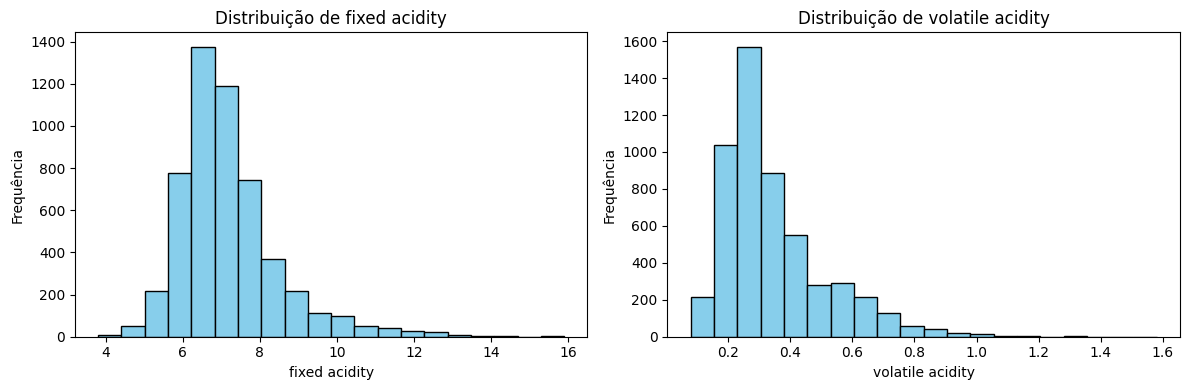

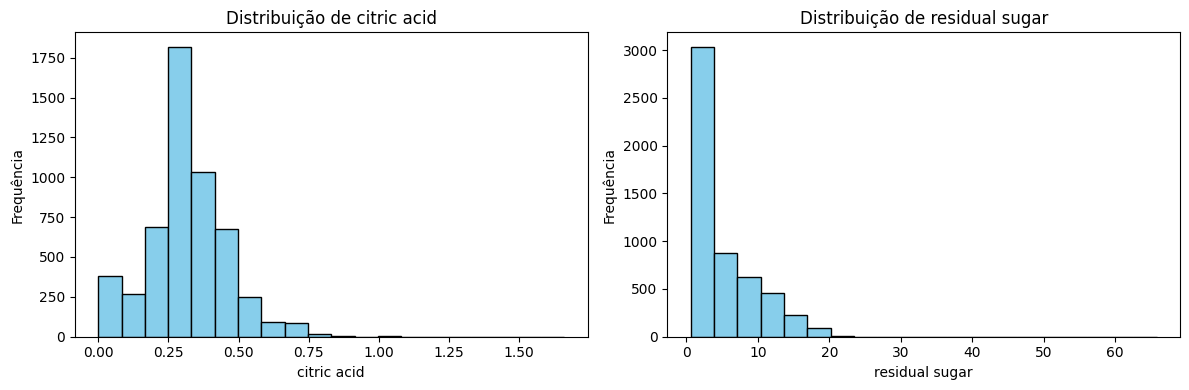

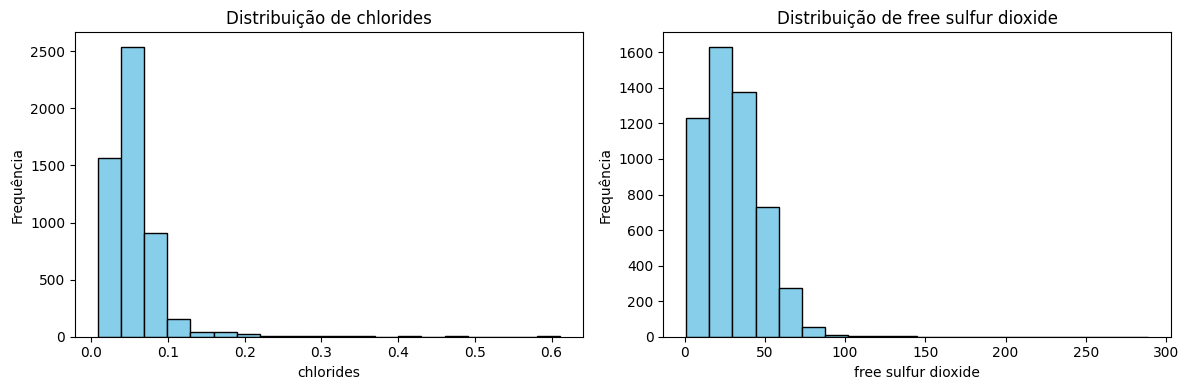

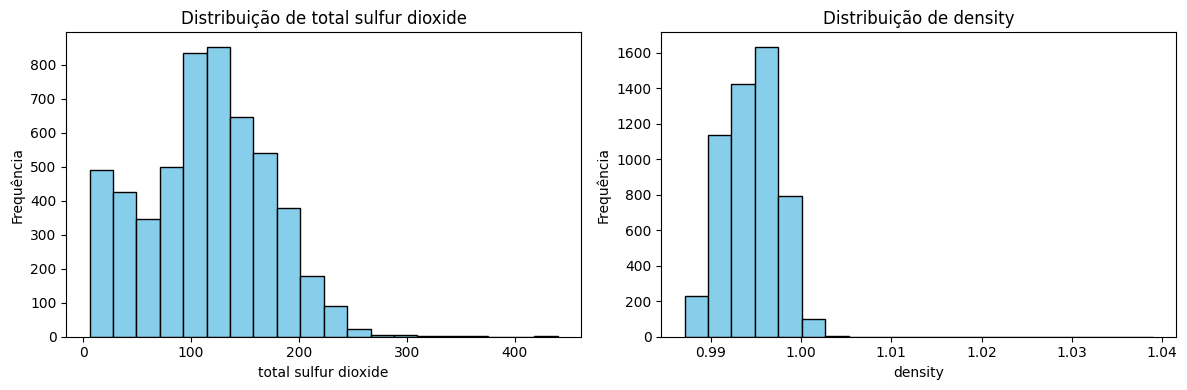

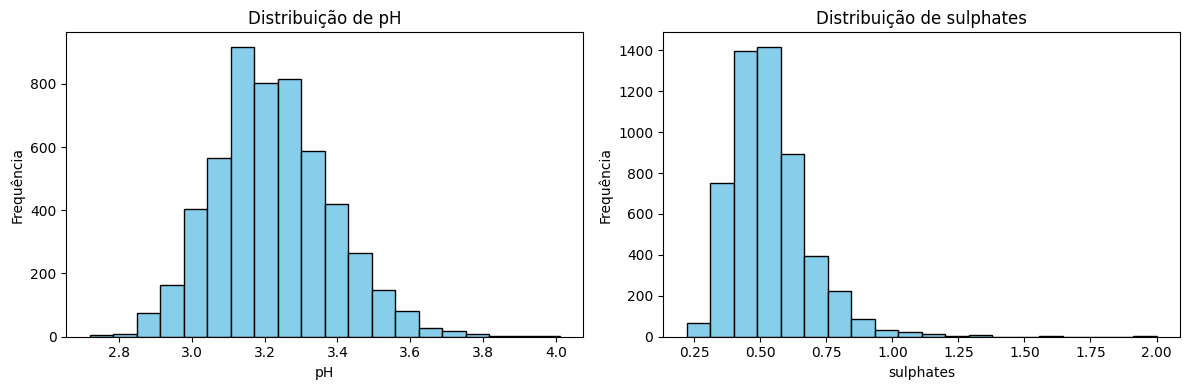

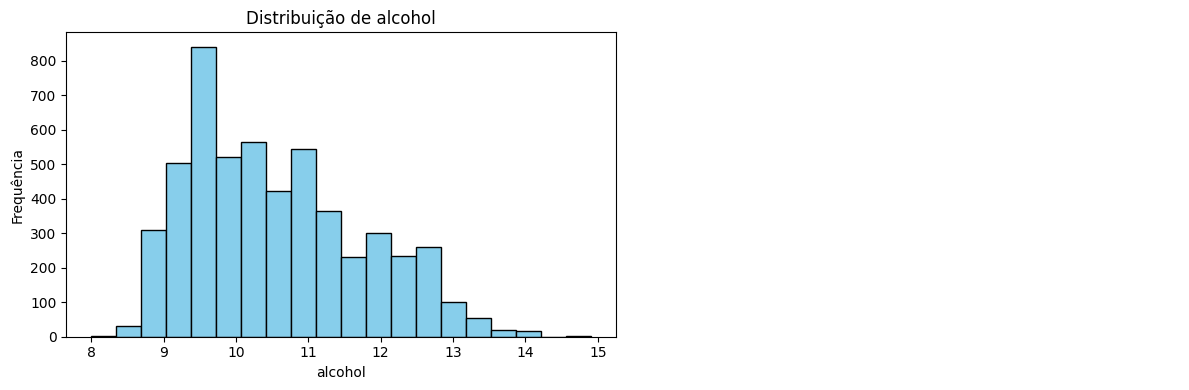

In [82]:
for i in range(0, len(colunas_numericas), 2):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    coluna1 = colunas_numericas[i]

    ax[0].hist(
        wine[coluna1],
        bins=20,
        color="skyblue",
        edgecolor="black"
    )
    ax[0].set_title(f"Distribuição de {coluna1}")
    ax[0].set_xlabel(coluna1)
    ax[0].set_ylabel("Frequência")

    if i + 1 < len(colunas_numericas):
        coluna2 = colunas_numericas[i + 1]
        ax[1].hist(
            wine[coluna2],
            bins=20,
            color="skyblue",
            edgecolor="black"
        )
        ax[1].set_title(f"Distribuição de {coluna2}")
        ax[1].set_xlabel(coluna2)
        ax[1].set_ylabel("Frequência")
    else:
        ax[1].axis("off")

    plt.tight_layout()
    plt.show()

A análise dos histogramas evidencia diferentes padrões de distribuição entre as propriedades físico-químicas dos vinhos. Algumas variáveis, como residual sugar, chlorides, free sulfur dioxide e volatile acidity, apresentam assimetria à direita, com maior concentração de observações em valores menores e caudas estendidas para valores mais elevados. Outras, como pH, apresentam distribuição mais próxima da simetria. Também são observadas diferenças significativas de escala entre os atributos, aspecto especialmente relevante para algoritmos baseados em distância, como o KNN.

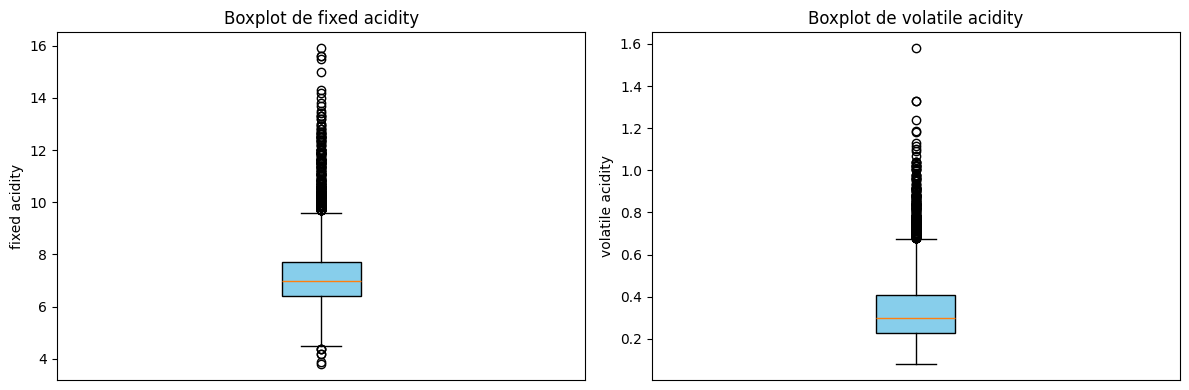

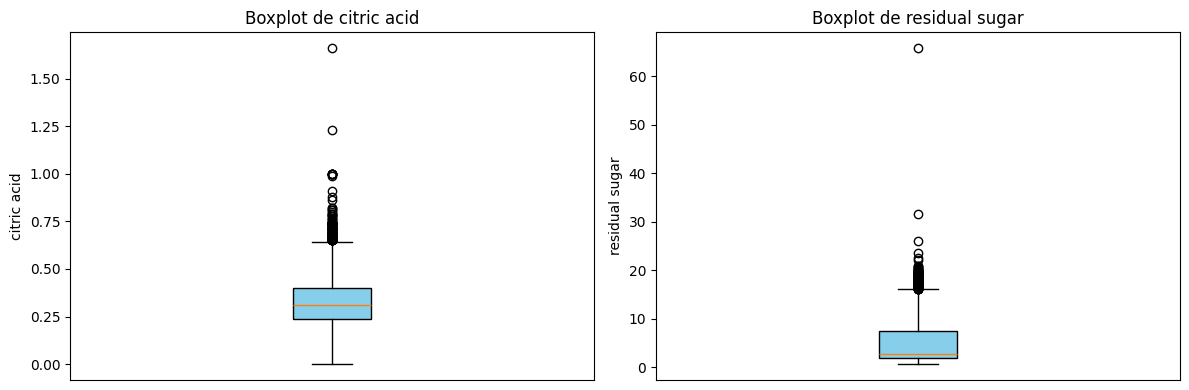

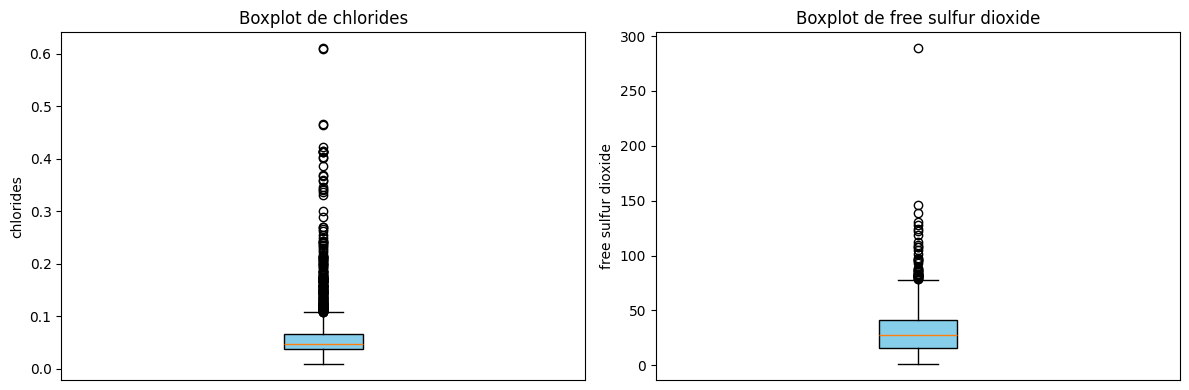

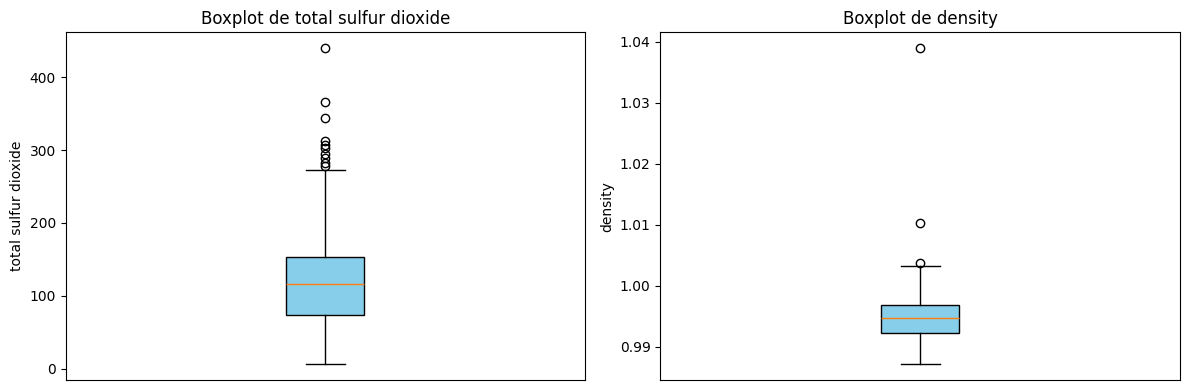

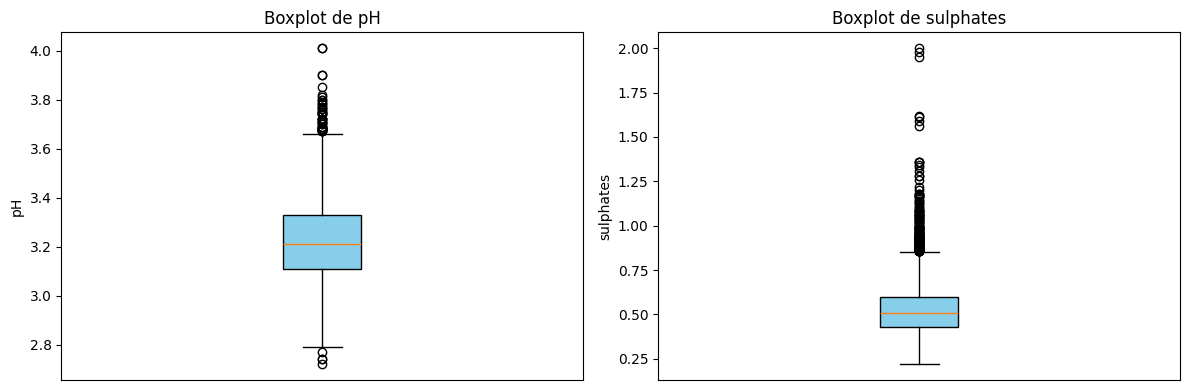

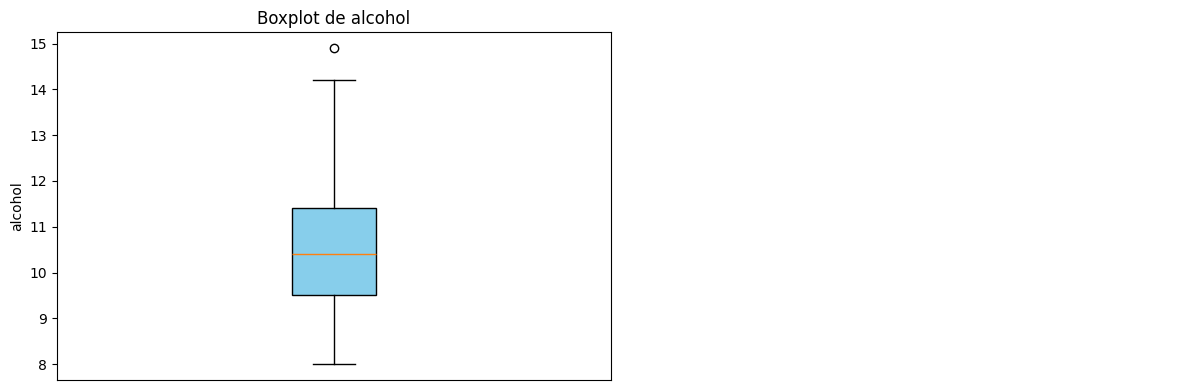

In [83]:
for i in range(0, len(colunas_numericas), 2):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    coluna1 = colunas_numericas[i]

    ax[0].boxplot(
        wine[coluna1],
        patch_artist=True,
        boxprops=dict(facecolor="skyblue", edgecolor="black")
    )
    ax[0].set_title(f"Boxplot de {coluna1}")
    ax[0].set_ylabel(coluna1)
    ax[0].set_xticks([])

    if i + 1 < len(colunas_numericas):
        coluna2 = colunas_numericas[i + 1]
        ax[1].boxplot(
            wine[coluna2],
            patch_artist=True,
            boxprops=dict(facecolor="skyblue", edgecolor="black")
        )
        ax[1].set_title(f"Boxplot de {coluna2}")
        ax[1].set_ylabel(coluna2)
        ax[1].set_xticks([])
    else:
        ax[1].axis("off")

    plt.tight_layout()
    plt.show()

A análise dos boxplots evidencia a presença de valores considerados atípicos em diversas propriedades físico-químicas dos vinhos, especialmente em variáveis como residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide e sulphates. Entretanto, esses valores não serão removidos automaticamente, pois podem representar características legítimas das amostras analisadas. Dessa forma, sua influência será considerada posteriormente durante o treinamento e a avaliação dos modelos.

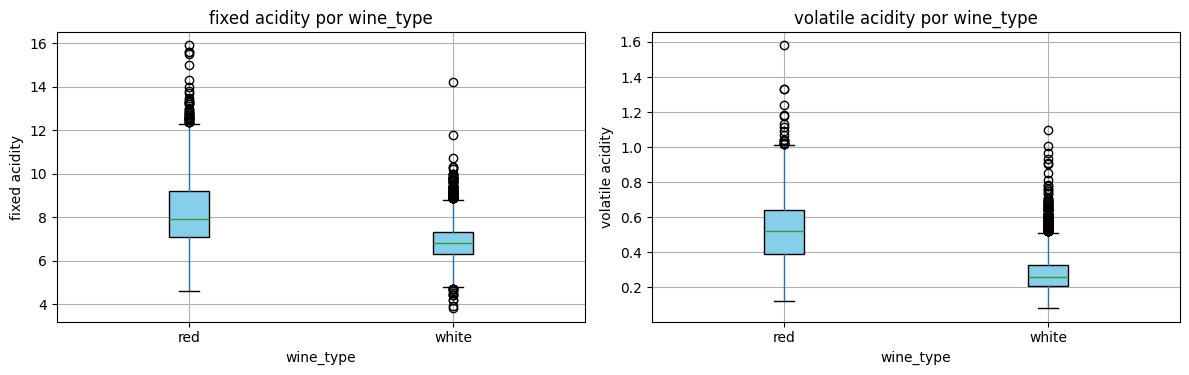

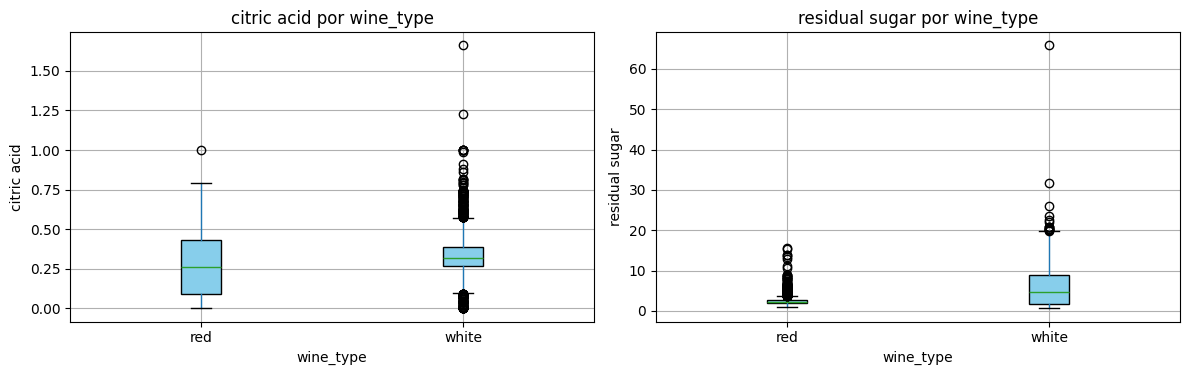

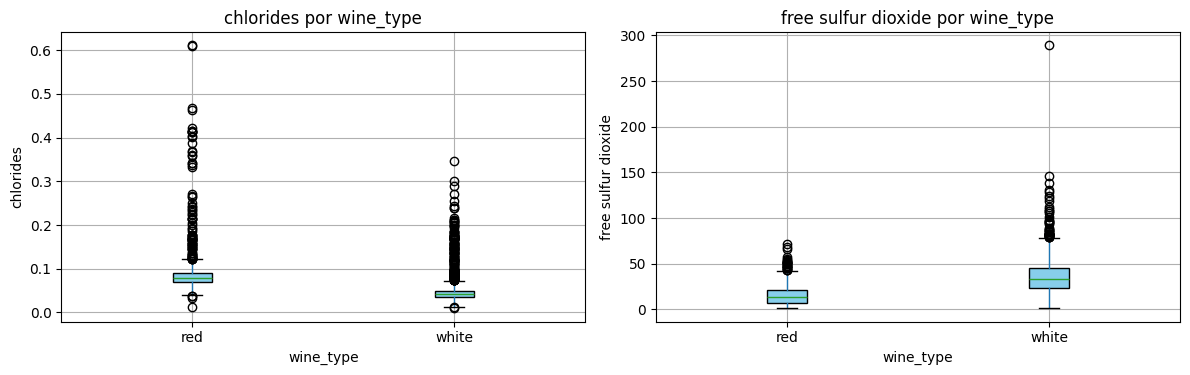

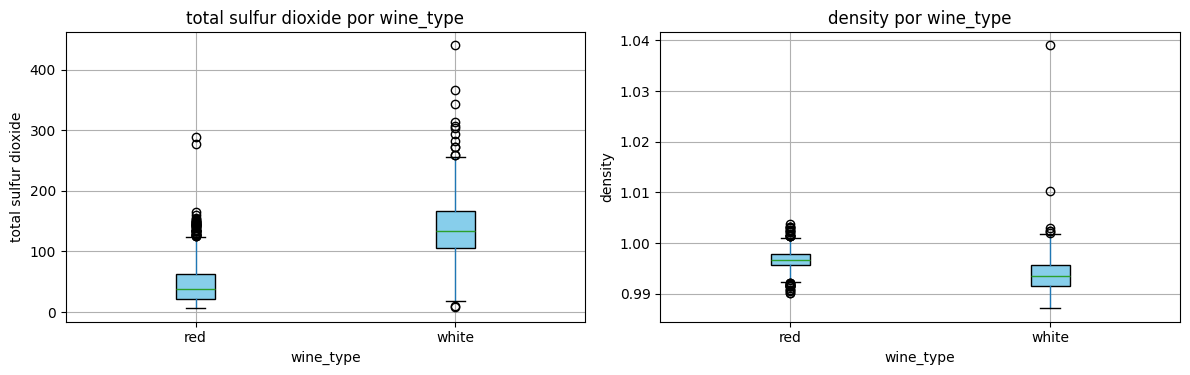

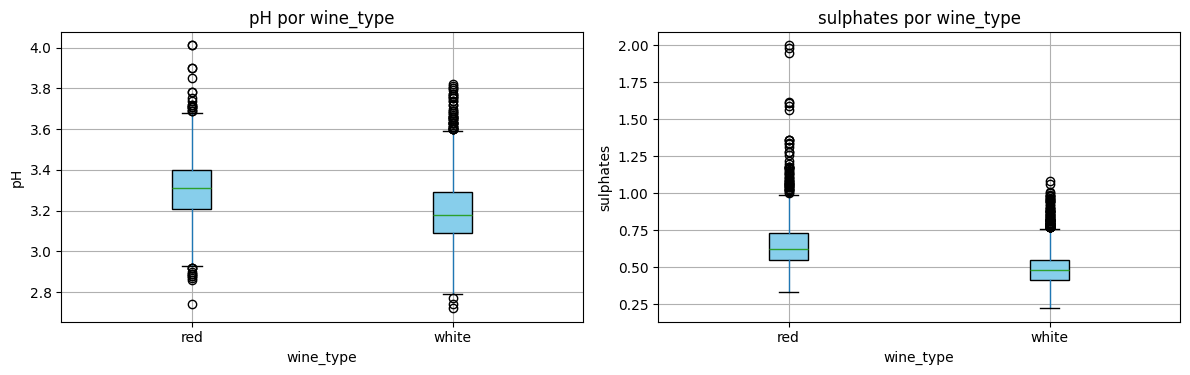

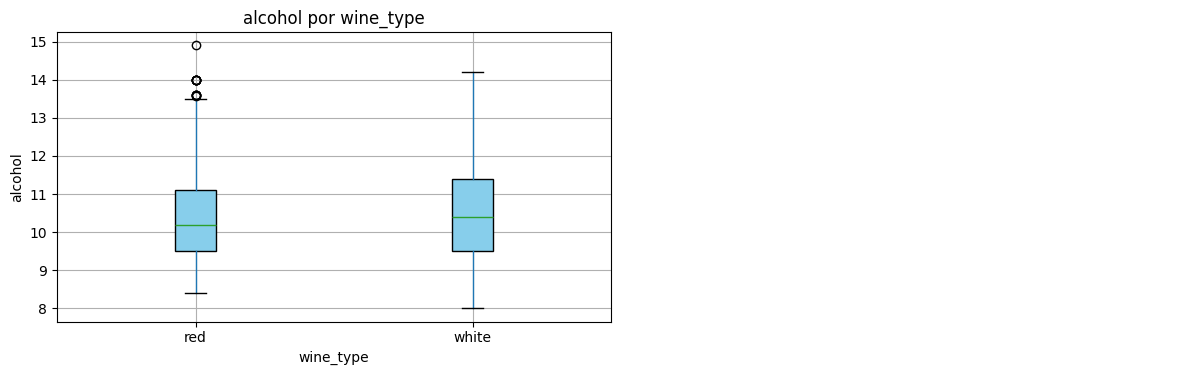

In [84]:
for i in range(0, len(colunas_numericas), 2):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    coluna1 = colunas_numericas[i]

    wine.boxplot(
        column=coluna1,
        by="wine_type",
        ax=ax[0],
        patch_artist=True,
        boxprops=dict(facecolor="skyblue", edgecolor="black")
    )
    ax[0].set_title(f"{coluna1} por wine_type")
    ax[0].set_xlabel("wine_type")
    ax[0].set_ylabel(coluna1)

    if i + 1 < len(colunas_numericas):
        coluna2 = colunas_numericas[i + 1]
        wine.boxplot(
            column=coluna2,
            by="wine_type",
            ax=ax[1],
            patch_artist=True,
            boxprops=dict(facecolor="skyblue", edgecolor="black")
        )
        ax[1].set_title(f"{coluna2} por wine_type")
        ax[1].set_xlabel("wine_type")
        ax[1].set_ylabel(coluna2)
    else:
        ax[1].axis("off")

    plt.suptitle("")
    plt.tight_layout()
    plt.show()

A comparação das variáveis físico-químicas de acordo com wine_type evidencia diferenças entre as distribuições dos vinhos tintos e brancos. Algumas variáveis, como volatile acidity, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH e sulphates, apresentam diferenças perceptíveis de mediana e distribuição entre as classes. Em contrapartida, variáveis como alcohol apresentam maior sobreposição entre os grupos. Esses resultados sugerem que determinadas propriedades físico-químicas possuem potencial discriminativo para a classificação do tipo de vinho, embora o desempenho efetivo deva ser confirmado pelos modelos de Machine Learning.

### 7. Hipótese 1: Existe relação entre o açúcar residual e a densidade do vinho?

Espera-se que amostras com maior concentração de açúcar residual (residual sugar) apresentem maior densidade (density), uma vez que a quantidade de substâncias dissolvidas pode influenciar a densidade do vinho. Além disso, será observado se os vinhos tintos e brancos apresentam comportamentos distintos nessa relação.

Correlação de Pearson entre residual sugar e density: 0.5209
Correlação entre residual sugar e density para red: 0.3245
Correlação entre residual sugar e density para white: 0.8205



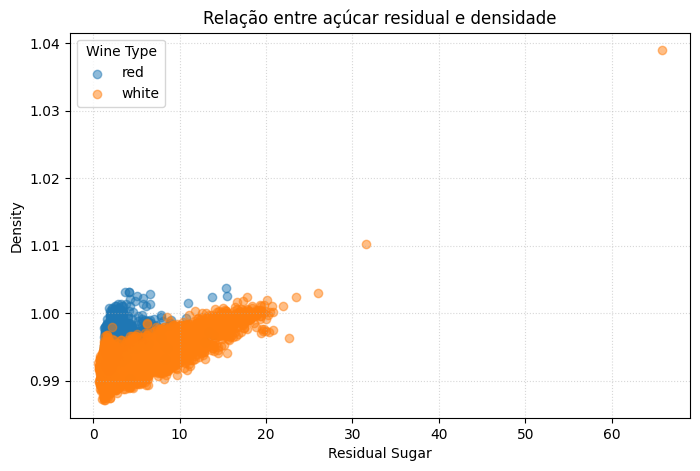

In [85]:
matriz_corr = np.corrcoef(
    wine["residual sugar"],
    wine["density"]
)

coef_correlacao = matriz_corr[0, 1]

print(
    f"Correlação de Pearson entre residual sugar e density: {coef_correlacao:.4f}"
)

for tipo, grupo in wine.groupby("wine_type"):
    correlacao_tipo = grupo["residual sugar"].corr(
        grupo["density"]
    )

    print(
        f"Correlação entre residual sugar e density para {tipo}: "
        f"{correlacao_tipo:.4f}"
    )

plt.figure(figsize=(8, 5))

for tipo, grupo in wine.groupby("wine_type"):
    plt.scatter(
        grupo["residual sugar"],
        grupo["density"],
        alpha=0.5,
        label=tipo
    )

print("")
plt.title("Relação entre açúcar residual e densidade")
plt.xlabel("Residual Sugar")
plt.ylabel("Density")
plt.legend(title="Wine Type")
plt.grid(True, linestyle=":", alpha=0.5)

plt.show()

Os resultados apresentam evidências favoráveis à hipótese de que maiores concentrações de açúcar residual estão associadas a maiores valores de densidade. Considerando todas as amostras, o coeficiente de correlação de Pearson foi de aproximadamente 0,52, indicando uma relação linear positiva moderada. Entretanto, a análise separada por tipo de vinho revela comportamentos distintos: nos vinhos tintos, a correlação foi de aproximadamente 0,32, indicando uma associação positiva mais fraca, enquanto nos vinhos brancos o coeficiente atingiu aproximadamente 0,82, caracterizando uma forte relação positiva. Dessa forma, a associação entre açúcar residual e densidade é consideravelmente mais intensa entre os vinhos brancos.

### 8. Hipótese 2: Existe relação entre dióxido de enxofre livre e dióxido de enxofre total?


Espera-se uma relação positiva entre free sulfur dioxide e total sulfur dioxide, uma vez que o dióxido de enxofre livre representa uma parcela do dióxido de enxofre total presente no vinho. Também será investigado se essa relação apresenta diferenças entre vinhos tintos e brancos.

Correlação de Pearson entre free sulfur dioxide e total sulfur dioxide: 0.7205
Correlação entre free sulfur dioxide e total sulfur dioxide para red: 0.6672
Correlação entre free sulfur dioxide e total sulfur dioxide para white: 0.6194
 


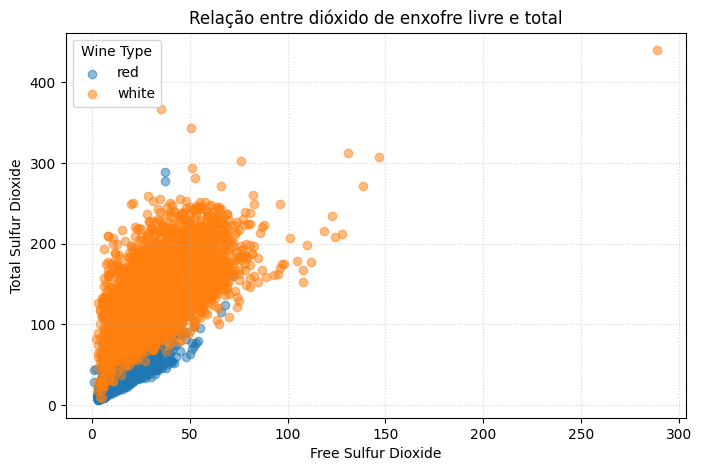

In [86]:
matriz_corr = np.corrcoef(
    wine["free sulfur dioxide"],
    wine["total sulfur dioxide"]
)

coef_correlacao = matriz_corr[0, 1]

print(f"Correlação de Pearson entre free sulfur dioxide e total sulfur dioxide: {coef_correlacao:.4f}")

for tipo, grupo in wine.groupby("wine_type"):
    correlacao_tipo = grupo[
        "free sulfur dioxide"
    ].corr(
        grupo["total sulfur dioxide"]
    )

    print(
        f"Correlação entre free sulfur dioxide e total sulfur dioxide para {tipo}: {correlacao_tipo:.4f}"
    )

plt.figure(figsize=(8, 5))

for tipo, grupo in wine.groupby("wine_type"):
    plt.scatter(
        grupo["free sulfur dioxide"],
        grupo["total sulfur dioxide"],
        alpha=0.5,
        label=tipo
    )

print(" ")
plt.title("Relação entre dióxido de enxofre livre e total")
plt.xlabel("Free Sulfur Dioxide")
plt.ylabel("Total Sulfur Dioxide")
plt.legend(title="Wine Type")
plt.grid(True, linestyle=":", alpha=0.5)

plt.show()

Os resultados confirmam a hipótese de uma relação positiva entre free sulfur dioxide e total sulfur dioxide. Considerando todas as amostras, o coeficiente de correlação de Pearson foi de aproximadamente 0,72, indicando uma associação linear positiva expressiva entre as variáveis. Ao analisar os tipos de vinho separadamente, a relação também se manteve positiva, com coeficientes de aproximadamente 0,67 para os vinhos tintos e 0,62 para os vinhos brancos. Dessa forma, maiores concentrações de dióxido de enxofre livre tendem a estar associadas a maiores concentrações de dióxido de enxofre total em ambos os grupos.

### 9. Hipótese 3: Existe relação entre a acidez fixa e o pH do vinho?

Espera-se que vinhos com maiores valores de fixed acidity apresentem menores valores de pH, indicando uma relação inversa entre essas propriedades. Também será investigado se essa relação apresenta comportamentos diferentes entre vinhos tintos e brancos.

Correlação de Pearson entre fixed acidity e pH: -0.2712
Correlação entre fixed acidity e pH para red: -0.6867
Correlação entre fixed acidity e pH para white: -0.4313



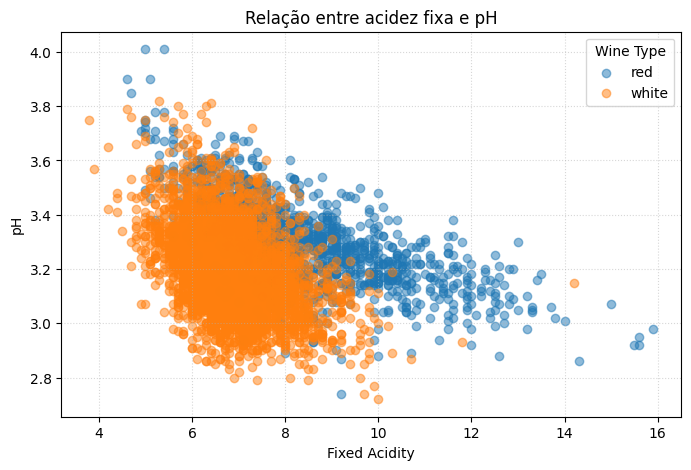

In [87]:
matriz_corr = np.corrcoef(
    wine["fixed acidity"],
    wine["pH"]
)

coef_correlacao = matriz_corr[0, 1]

print(
    f"Correlação de Pearson entre fixed acidity e pH: "
    f"{coef_correlacao:.4f}"
)

for tipo, grupo in wine.groupby("wine_type"):
    correlacao_tipo = grupo["fixed acidity"].corr(
        grupo["pH"]
    )

    print(
        f"Correlação entre fixed acidity e pH para {tipo}: "
        f"{correlacao_tipo:.4f}"
    )

plt.figure(figsize=(8, 5))

for tipo, grupo in wine.groupby("wine_type"):
    plt.scatter(
        grupo["fixed acidity"],
        grupo["pH"],
        alpha=0.5,
        label=tipo
    )

print("")
plt.title("Relação entre acidez fixa e pH")
plt.xlabel("Fixed Acidity")
plt.ylabel("pH")
plt.legend(title="Wine Type")
plt.grid(True, linestyle=":", alpha=0.5)

plt.show()

Os resultados apresentam evidências favoráveis à hipótese de uma relação inversa entre fixed acidity e pH. Considerando todas as amostras, o coeficiente de correlação de Pearson foi de aproximadamente -0,27, indicando uma associação linear negativa relativamente fraca.

Entretanto, a análise separada por tipo de vinho revela uma relação mais expressiva: para os vinhos tintos, o coeficiente foi de aproximadamente -0,69, indicando uma associação negativa moderada a forte, enquanto para os vinhos brancos foi de aproximadamente -0,43, caracterizando uma relação negativa moderada.

Assim, maiores valores de acidez fixa tendem a estar associados a menores valores de pH, principalmente entre os vinhos tintos. A diferença entre a correlação geral e as correlações calculadas separadamente reforça a importância de considerar o tipo de vinho durante a interpretação das relações entre as variáveis.

### 10. Análise de correlação

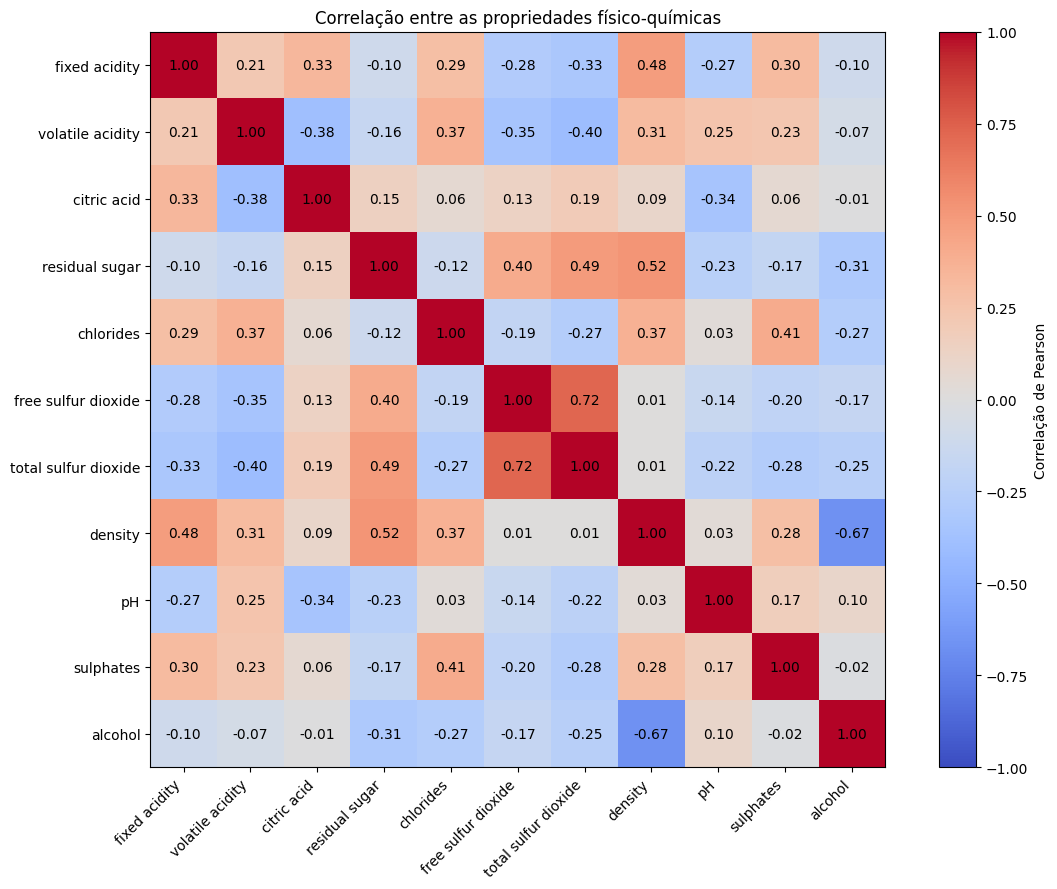

In [88]:
correlacao = wine[colunas_numericas].corr()

fig, ax = plt.subplots(figsize=(12, 9))

imagem = ax.imshow(
    correlacao,
    cmap='coolwarm',
    interpolation='none',
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    range(len(colunas_numericas)),
    colunas_numericas,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(colunas_numericas)),
    colunas_numericas
)

for i in range(len(colunas_numericas)):
    for j in range(len(colunas_numericas)):
        ax.text(
            j,
            i,
            f"{correlacao.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    imagem,
    ax=ax,
    label="Correlação de Pearson"
)

ax.set_title("Correlação entre as propriedades físico-químicas")

plt.tight_layout()
plt.show()

A matriz de correlação evidencia diferentes níveis de associação linear entre as propriedades físico-químicas dos vinhos. A relação positiva mais expressiva ocorre entre free sulfur dioxide e total sulfur dioxide, com coeficiente de aproximadamente 0,72. Também se destaca a correlação negativa entre density e alcohol, próxima de -0,67. Outras relações moderadas são observadas entre residual sugar e density (0,52), residual sugar e total sulfur dioxide (0,49) e fixed acidity e density (0,48). Esses resultados mostram que algumas variáveis apresentam associações lineares relevantes, enquanto outras possuem associações mais fracas. Ressalta-se que correlação não implica causalidade e que relações não lineares podem não ser plenamente representadas pelo coeficiente de Pearson.

### 11. Tratamento e preparação dos dados

Após a análise exploratória, inicia-se a preparação dos dados para os modelos de Machine Learning. Nesta etapa, são separadas as variáveis preditoras e a variável alvo wine_type. A variável quality não será utilizada como preditora, uma vez que o objetivo consiste em classificar o tipo de vinho exclusivamente a partir de suas propriedades físico-químicas.

In [89]:
X = wine.drop(columns=["wine_type", "quality"])
y = wine["wine_type"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Distribuição no Treino:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribuição no Teste:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Distribuição no Treino:
wine_type
white    74.46
red      25.54
Name: proportion, dtype: float64

Distribuição no Teste:
wine_type
white    74.44
red      25.56
Name: proportion, dtype: float64


Optou-se pela divisão de 80% dos dados para treinamento e 20% para teste, mantendo a maior parte das observações disponível para o aprendizado dos modelos e reservando uma parcela independente suficientemente representativa para sua avaliação. Após a divisão, foram destinadas 4.256 amostras ao conjunto de treinamento e 1.064 ao conjunto de teste. O parâmetro random_state=42 foi utilizado para garantir a reprodutibilidade da divisão.

A divisão estratificada preservou aproximadamente a distribuição original da variável alvo nos conjuntos de treinamento e teste. O conjunto de treinamento apresenta cerca de 74,46% de vinhos brancos e 25,54% de vinhos tintos, enquanto o conjunto de teste apresenta aproximadamente 74,44% de vinhos brancos e 25,56% de vinhos tintos. Dessa forma, a proporção entre as classes é mantida durante a avaliação dos modelos, reduzindo possíveis vieses decorrentes da divisão dos dados.

In [90]:
scaler = StandardScaler()

X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

Para o KNN, as variáveis foram padronizadas utilizando o StandardScaler, pois o algoritmo é baseado em medidas de distância e pode ser influenciado pelas diferentes escalas dos atributos. O ajuste do padronizador foi realizado exclusivamente sobre o conjunto de treinamento e posteriormente aplicado ao conjunto de teste. Para o Random Forest, a padronização não foi necessária, uma vez que o algoritmo é baseado em árvores de decisão.

### 12. Construção e treinamento dos modelos

Após a preparação dos dados, são construídos os modelos KNN e Random Forest. O KNN será treinado utilizando o conjunto de treinamento previamente padronizado, enquanto o Random Forest utilizará diretamente os valores originais das variáveis preditoras.

In [91]:
modelo_knn = KNeighborsClassifier()

modelo_rf = RandomForestClassifier(
    random_state=42
)

modelo_knn.fit(X_train_knn, y_train)
modelo_rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Após o treinamento, os modelos serão utilizados para realizar previsões sobre o conjunto de teste. Esses dados não participaram do ajuste dos modelos e serão utilizados para avaliar sua capacidade de generalização.

In [92]:
y_pred_knn = modelo_knn.predict(X_test_knn)
y_pred_rf = modelo_rf.predict(X_test)

As previsões obtidas serão comparadas com os valores reais do conjunto de teste. Inicialmente, será utilizada a acurácia, que representa a proporção de previsões corretas realizadas por cada modelo.

### 13. Avaliação inicial

In [93]:
acuracia_knn = accuracy_score(y_test, y_pred_knn)
acuracia_rf = accuracy_score(y_test, y_pred_rf)

print(f"Acurácia KNN: {acuracia_knn:.2%}")
print(f"Acurácia Random Forest: {acuracia_rf:.2%}")

Acurácia KNN: 99.34%
Acurácia Random Forest: 99.44%


In [94]:
print("Previsões do KNN:")
print(pd.Series(y_pred_knn).value_counts())

print("\nPrevisões do Random Forest:")
print(pd.Series(y_pred_rf).value_counts())

Previsões do KNN:
white    793
red      271
Name: count, dtype: int64

Previsões do Random Forest:
white    794
red      270
Name: count, dtype: int64


Os modelos apresentaram elevado desempenho já em suas configurações iniciais. O KNN obteve acurácia de aproximadamente 99,34%, enquanto o Random Forest alcançou aproximadamente 99,44%, ambos superando amplamente o requisito mínimo de 85%. Além disso, a distribuição das previsões entre as classes red e white permaneceu próxima à distribuição observada no conjunto de teste, indicando que os modelos não se limitaram a favorecer apenas a classe majoritária.

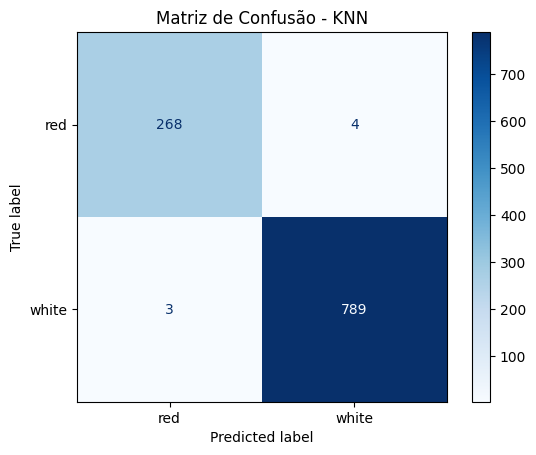

In [95]:
matriz_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=["red", "white"]
)

display_knn = ConfusionMatrixDisplay(
    confusion_matrix=matriz_knn,
    display_labels=["red", "white"]
)

display_knn.plot(cmap='Blues')
plt.title("Matriz de Confusão - KNN")
plt.show()

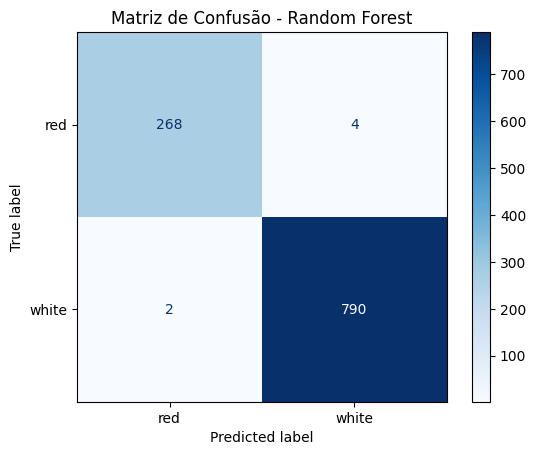

In [96]:
matriz_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=["red", "white"]
)

display_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["red", "white"]
)

display_rf.plot(cmap='Blues')
plt.title("Matriz de Confusão - Random Forest")
plt.show()

As matrizes de confusão demonstram elevado desempenho de ambos os classificadores na identificação dos tipos de vinho. O KNN classificou corretamente 268 amostras de vinho tinto e 789 de vinho branco, apresentando apenas sete erros no conjunto de teste. O Random Forest obteve desempenho ligeiramente superior, acertando 268 amostras de vinho tinto e 790 de vinho branco, com apenas seis classificações incorretas. Os resultados indicam que ambos os modelos conseguem distinguir adequadamente as classes red e white, inclusive a classe minoritária.

In [97]:
print("KNN:")
print(classification_report(y_test, y_pred_knn))

print("\nRandom Forest:")
print(classification_report(y_test, y_pred_rf))

KNN:
              precision    recall  f1-score   support

         red       0.99      0.99      0.99       272
       white       0.99      1.00      1.00       792

    accuracy                           0.99      1064
   macro avg       0.99      0.99      0.99      1064
weighted avg       0.99      0.99      0.99      1064


Random Forest:
              precision    recall  f1-score   support

         red       0.99      0.99      0.99       272
       white       0.99      1.00      1.00       792

    accuracy                           0.99      1064
   macro avg       0.99      0.99      0.99      1064
weighted avg       0.99      0.99      0.99      1064



Os relatórios de classificação confirmam o elevado desempenho dos modelos na identificação das duas classes. Tanto o KNN quanto o Random Forest apresentaram valores de precision, recall e F1-score próximos de 0,99 ou 1,00 para vinhos tintos e brancos. O desempenho equilibrado entre as classes demonstra que os modelos não se limitaram a favorecer a classe majoritária white. Embora o Random Forest tenha apresentado acurácia ligeiramente superior, a diferença entre os modelos foi muito pequena, correspondendo a apenas uma classificação adicional correta no conjunto de teste.

### 14. Otimização dos hiperparâmetros

Nesta etapa, são investigadas diferentes configurações de hiperparâmetros para os modelos. Para o KNN, a busca é realizada manualmente utilizando validação cruzada estratificada, permitindo que o StandardScaler seja ajustado exclusivamente sobre a parcela de treinamento de cada fold. Para o Random Forest, é utilizado o GridSearchCV, uma vez que esse algoritmo não necessita de padronização das variáveis.

In [98]:
parametros_knn = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

melhor_f1 = 0
melhores_parametros_knn = None

for n_neighbors in parametros_knn["n_neighbors"]:
    for weights in parametros_knn["weights"]:

        f1_folds = []

        for indice_treino, indice_validacao in cv.split(
            X_train,
            y_train
        ):
            X_treino_fold = X_train.iloc[indice_treino]
            X_validacao_fold = X_train.iloc[indice_validacao]

            y_treino_fold = y_train.iloc[indice_treino]
            y_validacao_fold = y_train.iloc[indice_validacao]

            scaler_fold = StandardScaler()

            X_treino_fold = scaler_fold.fit_transform(
                X_treino_fold
            )

            X_validacao_fold = scaler_fold.transform(
                X_validacao_fold
            )

            modelo = KNeighborsClassifier(
                n_neighbors=n_neighbors,
                weights=weights
            )

            modelo.fit(
                X_treino_fold,
                y_treino_fold
            )

            predicoes = modelo.predict(
                X_validacao_fold
            )

            f1 = f1_score(
                y_validacao_fold,
                predicoes,
                average="macro"
            )

            f1_folds.append(f1)

        media_f1 = np.mean(f1_folds)

        if media_f1 > melhor_f1:
            melhor_f1 = media_f1

            melhores_parametros_knn = {
                "n_neighbors": n_neighbors,
                "weights": weights
            }

print("Melhores parâmetros:")
print(melhores_parametros_knn)

print("\nMelhor F1-macro na validação cruzada:")
print(melhor_f1)

modelo_knn_otimizado = KNeighborsClassifier(
    n_neighbors=melhores_parametros_knn["n_neighbors"],
    weights=melhores_parametros_knn["weights"]
)

modelo_knn_otimizado.fit(
    X_train_knn,
    y_train
)

Melhores parâmetros:
{'n_neighbors': 11, 'weights': 'distance'}

Melhor F1-macro na validação cruzada:
0.9892032648630625


KNeighborsClassifier(n_neighbors=11, weights='distance')

A busca manual de hiperparâmetros com validação cruzada estratificada indicou n_neighbors=11 e weights='distance' como a melhor configuração para o KNN. Durante o processo, o StandardScaler foi ajustado exclusivamente sobre a parcela de treinamento de cada fold, evitando que informações da parcela de validação influenciassem a padronização. A melhor configuração apresentou F1-macro médio de aproximadamente 98,92%.

In [99]:
parametros_rf = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42
    ),
    param_grid=parametros_rf,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Melhores parâmetros:")
print(grid_rf.best_params_)

print("\nMelhor F1-macro na validação cruzada:")
print(grid_rf.best_score_)

Melhores parâmetros:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

Melhor F1-macro na validação cruzada:
0.9919220521679755


Para o Random Forest, a busca de hiperparâmetros indicou como melhor configuração 100 árvores, profundidade máxima igual a 10 e mínimo de 2 amostras para divisão dos nós. O modelo apresentou F1-macro médio de aproximadamente 99,19% durante a validação cruzada, resultado ligeiramente superior aos 98,92% obtidos pelo KNN.

### 15. Validação cruzada dos modelos otimizados

In [100]:
acuracias_knn = []

for indice_treino, indice_validacao in cv.split(
    X_train,
    y_train
):
    X_treino_fold = X_train.iloc[indice_treino]
    X_validacao_fold = X_train.iloc[indice_validacao]

    y_treino_fold = y_train.iloc[indice_treino]
    y_validacao_fold = y_train.iloc[indice_validacao]

    scaler_fold = StandardScaler()

    X_treino_fold = scaler_fold.fit_transform(
        X_treino_fold
    )

    X_validacao_fold = scaler_fold.transform(
        X_validacao_fold
    )

    modelo_fold = KNeighborsClassifier(
        n_neighbors=melhores_parametros_knn["n_neighbors"],
        weights=melhores_parametros_knn["weights"]
    )

    modelo_fold.fit(
        X_treino_fold,
        y_treino_fold
    )

    predicoes_fold = modelo_fold.predict(
        X_validacao_fold
    )

    acuracia = accuracy_score(
        y_validacao_fold,
        predicoes_fold
    )

    acuracias_knn.append(acuracia)

acuracias_knn = np.array(acuracias_knn)

acuracias_rf = cross_val_score(
    grid_rf.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Acurácias KNN:")
print(acuracias_knn)
print(f"Média KNN: {acuracias_knn.mean():.2%}")

print("\nAcurácias Random Forest:")
print(acuracias_rf)
print(f"Média Random Forest: {acuracias_rf.mean():.2%}")

Acurácias KNN:
[0.98591549 0.99412456 0.99647474 0.98824912 0.99412456]
Média KNN: 99.18%

Acurácias Random Forest:
[0.98826291 0.99764982 0.99529965 0.99294947 0.99529965]
Média Random Forest: 99.39%


A validação cruzada estratificada demonstrou desempenho elevado e consistente para ambos os modelos. O KNN apresentou acurácia média de aproximadamente 99,18%, enquanto o Random Forest alcançou 99,39%. Em todas as divisões avaliadas, os resultados permaneceram amplamente superiores ao requisito mínimo de 85%.

No caso do KNN, a padronização foi ajustada separadamente sobre a parcela de treinamento de cada fold, impedindo que informações da parcela de validação fossem utilizadas no cálculo dos parâmetros do StandardScaler. Os resultados indicam elevada estabilidade dos classificadores e sugerem boa capacidade de generalização.

### 16.  Avaliação dos modelos otimizados

In [101]:
y_pred_knn_otimizado = modelo_knn_otimizado.predict(
    X_test_knn
)

y_pred_rf_otimizado = grid_rf.best_estimator_.predict(
    X_test
)

acuracia_knn_otimizado = accuracy_score(
    y_test,
    y_pred_knn_otimizado
)

acuracia_rf_otimizado = accuracy_score(
    y_test,
    y_pred_rf_otimizado
)

print(
    f"Acurácia KNN otimizado: "
    f"{acuracia_knn_otimizado:.2%}"
)

print(
    f"Acurácia Random Forest otimizado: "
    f"{acuracia_rf_otimizado:.2%}"
)

Acurácia KNN otimizado: 99.25%
Acurácia Random Forest otimizado: 99.44%


Após a seleção dos hiperparâmetros, o KNN apresentou acurácia de 99,25% no conjunto de teste, enquanto o Random Forest alcançou 99,44%. Em relação às configurações iniciais, o KNN passou de 99,34% para 99,25%, enquanto o Random Forest manteve sua acurácia de 99,44%. A pequena redução observada no KNN não representa necessariamente uma piora do processo de otimização, uma vez que os hiperparâmetros foram selecionados com base no F1-macro médio obtido durante a validação cruzada, e não diretamente pela acurácia do conjunto de teste.

In [102]:
print("KNN otimizado:")
print(
    classification_report(
        y_test,
        y_pred_knn_otimizado
    )
)

print("\nRandom Forest otimizado:")
print(
    classification_report(
        y_test,
        y_pred_rf_otimizado
    )
)

KNN otimizado:
              precision    recall  f1-score   support

         red       0.99      0.99      0.99       272
       white       0.99      0.99      0.99       792

    accuracy                           0.99      1064
   macro avg       0.99      0.99      0.99      1064
weighted avg       0.99      0.99      0.99      1064


Random Forest otimizado:
              precision    recall  f1-score   support

         red       1.00      0.98      0.99       272
       white       0.99      1.00      1.00       792

    accuracy                           0.99      1064
   macro avg       0.99      0.99      0.99      1064
weighted avg       0.99      0.99      0.99      1064



Os relatórios de classificação mostram valores de precision, recall e F1-score próximos de 1,00 para ambas as classes. No Random Forest, a classe red apresentou precision de 1,00 e recall de 0,98, enquanto a classe white apresentou recall de 1,00. Dessa forma, mesmo diante da diferença na quantidade de amostras entre as classes, o modelo manteve elevado desempenho tanto para vinhos tintos quanto para vinhos brancos.

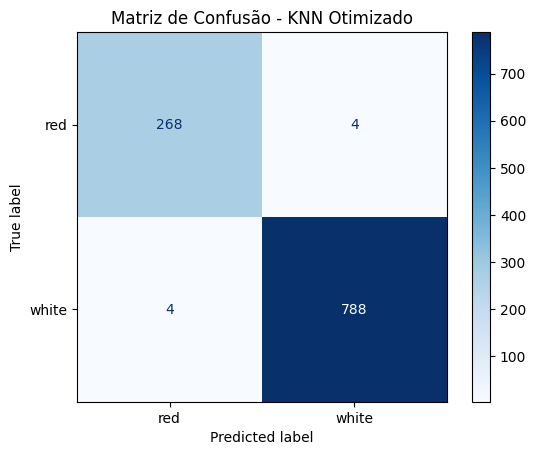

In [103]:
matriz_knn_otimizado = confusion_matrix(
    y_test,
    y_pred_knn_otimizado,
    labels=["red", "white"]
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_knn_otimizado,
    display_labels=["red", "white"]
).plot(cmap="Blues")

plt.title("Matriz de Confusão - KNN Otimizado")
plt.show()

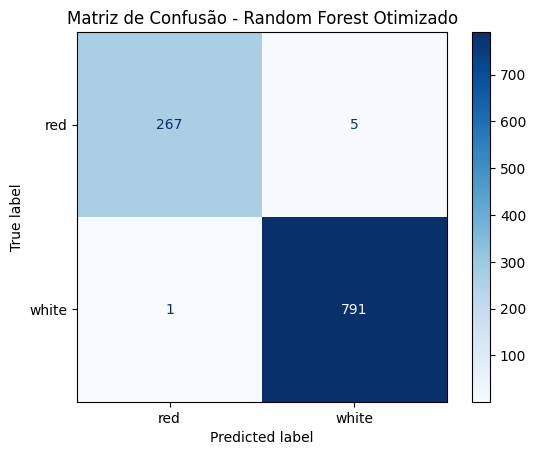

In [104]:
matriz_rf_otimizado = confusion_matrix(
    y_test,
    y_pred_rf_otimizado,
    labels=["red", "white"]
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf_otimizado,
    display_labels=["red", "white"]
).plot(cmap="Blues")

plt.title("Matriz de Confusão - Random Forest Otimizado")
plt.show()

As matrizes de confusão reforçam o elevado desempenho dos modelos. O KNN classificou corretamente 268 vinhos tintos e 788 vinhos brancos, apresentando apenas oito classificações incorretas entre as 1.064 amostras do conjunto de teste. O Random Forest classificou corretamente 267 vinhos tintos e 791 vinhos brancos, totalizando apenas seis erros.

Embora o KNN tenha reconhecido uma amostra adicional de vinho tinto corretamente, o Random Forest apresentou menor número total de erros e melhor desempenho global no conjunto de teste.

### 17. Comparação final dos modelos

In [105]:
comparacao = pd.DataFrame({
    "Modelo": [
        "KNN",
        "Random Forest"
    ],
    "Acurácia Inicial": [
        acuracia_knn,
        acuracia_rf
    ],
    "Acurácia Otimizada": [
        acuracia_knn_otimizado,
        acuracia_rf_otimizado
    ],
    "Acurácia Média CV": [
        acuracias_knn.mean(),
        acuracias_rf.mean()
    ],
    "F1-Macro CV": [
        melhor_f1,
        grid_rf.best_score_
    ]
})

comparacao.style.format({
    "Acurácia Inicial": "{:.2%}",
    "Acurácia Otimizada": "{:.2%}",
    "Acurácia Média CV": "{:.2%}",
    "F1-Macro CV": "{:.2%}"
})

,Modelo,Acurácia Inicial,Acurácia Otimizada,Acurácia Média CV,F1-Macro CV
0,KNN,99.34%,99.25%,99.18%,98.92%
1,Random Forest,99.44%,99.44%,99.39%,99.19%


A comparação final demonstra desempenho elevado para os dois algoritmos. O KNN apresentou acurácia inicial de 99,34% e acurácia de 99,25% após a seleção dos hiperparâmetros, enquanto o Random Forest manteve 99,44% nas duas avaliações.

Na validação cruzada, o Random Forest também apresentou resultado ligeiramente superior, com acurácia média de 99,39%, em comparação aos 99,18% do KNN. O mesmo comportamento foi observado no F1-macro médio utilizado durante a otimização, com 99,19% para o Random Forest e 98,92% para o KNN.

A validação cruzada e o F1-macro indicaram desempenho ligeiramente superior do Random Forest durante o processo de seleção dos modelos. A avaliação posterior no conjunto de teste confirmou esse comportamento, com acurácia de 99,44%. Dessa forma, o Random Forest foi selecionado como modelo final.

### 18. Importância das variáveis - Random Forest

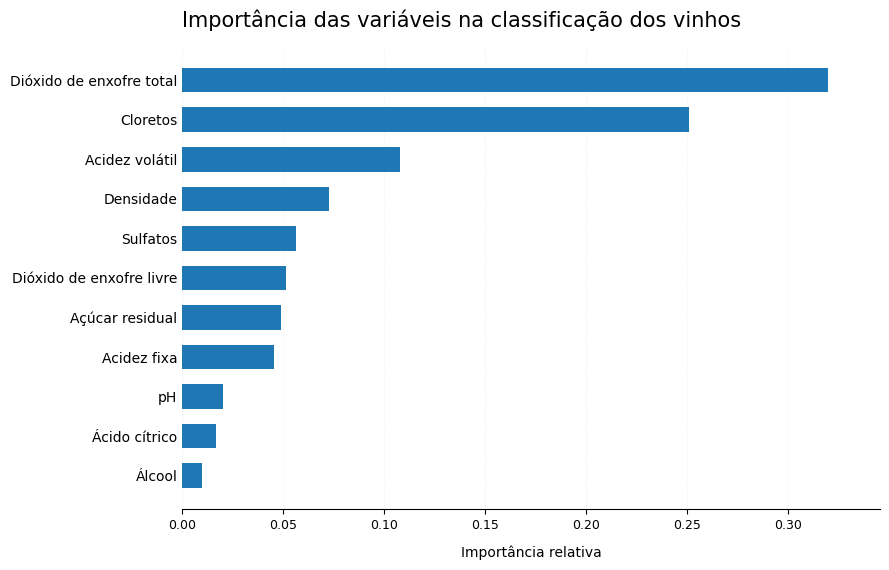

In [106]:
nomes_variaveis = {
    "total sulfur dioxide": "Dióxido de enxofre total",
    "chlorides": "Cloretos",
    "volatile acidity": "Acidez volátil",
    "density": "Densidade",
    "free sulfur dioxide": "Dióxido de enxofre livre",
    "residual sugar": "Açúcar residual",
    "sulphates": "Sulfatos",
    "fixed acidity": "Acidez fixa",
    "pH": "pH",
    "citric acid": "Ácido cítrico",
    "alcohol": "Álcool"
}

rf_final = grid_rf.best_estimator_

importancias = pd.DataFrame({
    "Variável": X.columns,
    "Importância": rf_final.feature_importances_
})

importancias = importancias.sort_values(
    by="Importância",
    ascending=False
).reset_index(drop=True)

importancias_grafico = importancias.copy()

importancias_grafico["Variável"] = (
    importancias_grafico["Variável"]
    .replace(nomes_variaveis)
)

fig, ax = plt.subplots(figsize=(9, 5.8))

ax.barh(
    importancias_grafico["Variável"],
    importancias_grafico["Importância"],
    height=0.62
)

ax.invert_yaxis()

ax.set_title(
    "Importância das variáveis na classificação dos vinhos",
    fontsize=15,
    loc="left",
    pad=14
)

ax.set_xlabel(
    "Importância relativa",
    fontsize=10,
    labelpad=10
)

ax.set_ylabel("")

ax.xaxis.grid(
    True,
    linestyle=":",
    alpha=0.18
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=10
)

ax.tick_params(
    axis="x",
    labelsize=9
)

ax.set_xlim(
    0,
    importancias_grafico["Importância"].max() * 1.08
)

plt.tight_layout()
plt.show()

A análise da importância das variáveis indica que o dióxido de enxofre total foi o atributo de maior contribuição para as decisões do Random Forest, seguido pelos cloretos e pela acidez volátil. A densidade também apresentou contribuição relevante para a classificação.

Em contrapartida, características como pH, ácido cítrico e teor alcoólico apresentaram menor importância relativa para as decisões do modelo. Os resultados reforçam diversas diferenças observadas anteriormente durante a análise exploratória dos vinhos tintos e brancos.

Ressalta-se que a importância das variáveis representa sua contribuição para as decisões realizadas pelas árvores do Random Forest e não deve ser interpretada como uma relação de causa e efeito.

### 19. Escolha e salvamento do modelo final

Após a comparação entre os modelos, o Random Forest foi selecionado como modelo final devido ao desempenho ligeiramente superior observado no conjunto de teste, na validação cruzada e na métrica F1-macro. O modelo otimizado será armazenado utilizando a biblioteca Joblib, permitindo sua reutilização posterior sem necessidade de novo treinamento.

Após o carregamento do arquivo salvo, o modelo manteve acurácia de 99,44% sobre o conjunto de teste, confirmando que o processo de persistência preservou corretamente o estimador treinado.

In [107]:
melhor_modelo = grid_rf.best_estimator_

joblib.dump(
    melhor_modelo,
    "modelo_random_forest_wine.joblib"
)

print("Modelo salvo com sucesso.")

modelo_carregado = joblib.load(
    "modelo_random_forest_wine.joblib"
)

previsoes_teste = modelo_carregado.predict(X_test)

acuracia_modelo_carregado = accuracy_score(
    y_test,
    previsoes_teste
)

print(
    f"Acurácia do modelo carregado: "
    f"{acuracia_modelo_carregado:.2%}"
)

Modelo salvo com sucesso.
Acurácia do modelo carregado: 99.44%


### 20. Conclusão

Este trabalho investigou a classificação de vinhos tintos e brancos a partir de propriedades físico-químicas utilizando os algoritmos K-Nearest Neighbors (KNN) e Random Forest.
Durante a análise exploratória, foram identificadas diferenças relevantes entre as classes em diversas características, além de relações entre propriedades físico-químicas investigadas por meio de análises de correlação e hipóteses.

Na etapa de modelagem, o KNN apresentou acurácia inicial de 99,34% e acurácia final de 99,25%, enquanto o Random Forest alcançou 99,44% tanto na configuração inicial quanto após a otimização. Na validação cruzada estratificada, foram obtidas acurácias médias de 99,18% para o KNN e 99,39% para o Random Forest. Os valores médios de F1-macro durante a otimização foram de aproximadamente 98,92% e 99,19%, respectivamente.

Para o KNN, a padronização foi realizada separadamente em cada divisão da validação cruzada, evitando que informações do conjunto de validação fossem utilizadas durante o ajuste do StandardScaler. O Random Forest apresentou desempenho ligeiramente superior nas diferentes formas de avaliação e, por isso, foi selecionado como modelo final.

A análise da importância das variáveis indicou maior contribuição do dióxido de enxofre total, dos cloretos e da acidez volátil para a classificação dos vinhos. Por fim, o modelo Random Forest otimizado foi armazenado utilizando a biblioteca Joblib, permitindo sua reutilização sem necessidade de novo treinamento.
Dessa forma, os resultados indicam que as propriedades físico-químicas disponíveis no conjunto Wine Quality permitem distinguir vinhos tintos e brancos com elevado desempenho, superando amplamente o requisito mínimo de 85% estabelecido para o projeto.

###